# Exploring the data: AI as substitute or complement

Interactive companion to `python -m aiprod.run`. Every cell reads the cached
data through the same functions the pipeline uses, so numbers here match the
tables in `output/tables/`. Figures shown inline can be saved with
`figures.save(fig, name)`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from aiprod import claims, inference, nowcast, panels, strategy
from aiprod.figures import AI_BLUE, IT_ORANGE, MUTED, COLUMN, FULL, apply_style, mark_event, save, zero_line

apply_style()
plt.rcParams["figure.dpi"] = 130
pd.set_option("display.width", 160)

## 1. Exposure: which sectors are "AI-exposed", and were they also "IT-exposed"?

In [2]:
sector_exp = panels.sector_exposures()
naics_exp = panels.naics2_exposures()
sector_exp.sort_values("ai_exposure", ascending=False).round(3)

,ai_exposure,it_share
finance,1.960,0.132
information,1.195,0.235
educ_health,0.922,0.031
prof_business,0.614,0.106
wholesale,0.294,0.116
retail,0.182,0.040
other_services,0.066,0.021
utilities,-0.005,0.017
leisure,-0.054,0.014
transport,-0.489,0.059


## 2. C2: juniors in exposed sectors

The junior gap is log employment of 22–24 year-olds minus log employment of
35–54 year-olds in the same sector and quarter (Census QWI). Change the
exposure split or the age groups in `config.py` and re-run this cell.

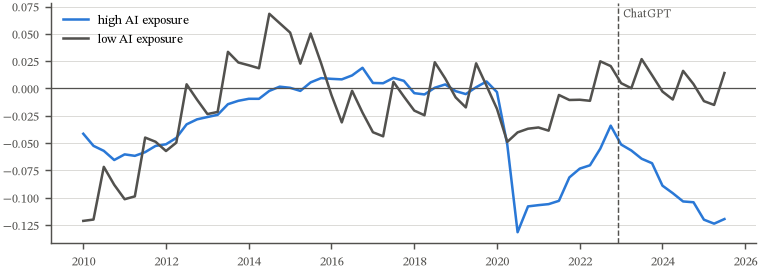

In [3]:
gaps = panels.qwi_age_gaps()
tercile = pd.qcut(naics_exp["ai_exposure"], 3, labels=["low", "mid", "high"])
by_group = (gaps.assign(group=gaps["industry"].map(tercile))
                .groupby(["date", "group"], observed=True)["emp_gap"].mean().unstack())

fig, ax = plt.subplots(figsize=(FULL, 2.4))
for group, color in (("high", AI_BLUE), ("low", MUTED)):
    series = by_group.loc["2010":, group]
    ax.plot(series.index, series - series.loc["2019"].mean(), color=color, label=f"{group} AI exposure")
zero_line(ax)
mark_event(ax, pd.Timestamp("2022-11-30"), "ChatGPT")
ax.legend()
plt.show()

## 3. Did the exposed-sector trend bend at ChatGPT?

COVID quarters are dropped; `post_covid` absorbs a level shift, `ramp_chatgpt`
is the change in slope after 2022Q4 (per SD of exposure, per year).

In [4]:
gaps_ai = gaps.assign(ai_exposure=gaps["industry"].map(naics_exp["ai_exposure"]))
inference.kink_test(gaps_ai, "emp_gap", "industry", "ai_exposure", ("log_emp_total",)).round(4)

,outcome,term,beta,t,p_boot,n_clusters
0,emp_gap,exposure:trend,0.0002,0.0601,0.9525,19
1,emp_gap,exposure:post_covid,-0.0560,-3.5288,0.0055,19
2,emp_gap,exposure:ramp_chatgpt,-0.0124,-2.2744,0.0135,19


## 4. C3: labor share, the incidence test

In [5]:
incidence = panels.incidence_panel()
estimates = claims.annual_era_did(incidence, sector_exp, "labor_share_change", "C3")
pd.DataFrame([e.__dict__ for e in estimates]).round(3)

,claim,era,outcome,beta,se,p_boot,n_obs,n_clusters
0,C3,IT,labor_share_change,0.006,0.280,0.987,221,13
1,C3,AI,labor_share_change,-0.809,0.112,0.002,169,13


## 5. Nowcast: filling the QWI publication lag with monthly data

In [6]:
nowcast_panel, fit = nowcast.junior_gap_nowcast(gaps)
print({k: round(v, 3) for k, v in fit.items()})
nowcast_panel.groupby("date")[["d_emp_gap", "nowcast"]].mean().loc["2022":].round(3)

{'oos_r2': 0.526, 'oos_corr': 0.766, 'n_oos': 187}


,d_emp_gap,nowcast
date,,
2022-01-01,0.033,0.066
2022-04-01,0.038,0.056
2022-07-01,0.042,0.051
2022-10-01,0.044,0.043
2023-01-01,0.026,0.027
2023-04-01,0.020,0.014
2023-07-01,0.006,0.014
2023-10-01,-0.008,0.004
2024-01-01,-0.009,0.003


## 6. C4: does the market price it?

In [7]:
returns = strategy.sector_returns()
backtest = strategy.backtest(strategy.substitution_scores(gaps), returns)
size = strategy.bayesian_sizing(backtest["ls"])
pd.DataFrame({
    "long S / short C": strategy.performance(backtest["ls"]["1996":], backtest["turnover"]["1996":]),
    "Bayesian-sized": strategy.performance((backtest["ls"] * size)["1996":]),
}).round(3)

,long S / short C,Bayesian-sized
mean,-0.018,-0.007
vol,0.093,0.056
sharpe,-0.188,-0.124
max_drawdown,-0.549,-0.281
turnover,1.271,NaN
months,369.000,369.000
